# Tech Challenge Fase 1: apoio ao diagnóstico de câncer de mama
Classificação de tumores de mama em maligno (1) ou benigno (0) com o dataset Breast Cancer Wisconsin (Diagnostic).
O resultado do modelo é uma sugestão de apoio à decisão; o diagnóstico cabe ao profissional de saúde.

O notebook segue a ordem do enunciado: dados, exploração, pré-processamento, modelagem, avaliação e interpretação.
A lógica está implementada e testada nos módulos de `src/`.

In [1]:
import sys; sys.path.append("..")
import pandas as pd
from IPython.display import Image, display
from src import data, eda, preprocessing, train, evaluate, explain

## 1. Dados
569 exames de punção aspirativa por agulha fina, com 30 medidas numéricas do núcleo celular (10 características
em três estatísticas: média, erro-padrão e maior valor). Não há valores ausentes nem variáveis categóricas.

In [2]:
df = data.load_data()
print(df.shape)
print("valores ausentes:", df.isna().sum().sum())
df.head()

(569, 31)
valores ausentes: 0


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


## 2. Análise exploratória
Balanceamento de 63% benigno e 37% maligno. Um classificador que sempre prevê benigno teria accuracy de 62,7%,
por isso a avaliação prioriza recall e F1.

In [3]:
display(eda.class_balance(df))
eda.describe(df).round(3)

,n,proporcao
target,,
benigno,357,0.627
maligno,212,0.373


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127,3.524,6.981,11.700,13.370,15.780,28.110
mean texture,569.0,19.290,4.301,9.710,16.170,18.840,21.800,39.280
mean perimeter,569.0,91.969,24.299,43.790,75.170,86.240,104.100,188.500
mean area,569.0,654.889,351.914,143.500,420.300,551.100,782.700,2501.000
mean smoothness,569.0,0.096,0.014,0.053,0.086,0.096,0.105,0.163
mean compactness,569.0,0.104,0.053,0.019,0.065,0.093,0.130,0.345
mean concavity,569.0,0.089,0.080,0.000,0.030,0.062,0.131,0.427
mean concave points,569.0,0.049,0.039,0.000,0.020,0.034,0.074,0.201
mean symmetry,569.0,0.181,0.027,0.106,0.162,0.179,0.196,0.304
mean fractal dimension,569.0,0.063,0.007,0.050,0.058,0.062,0.066,0.097


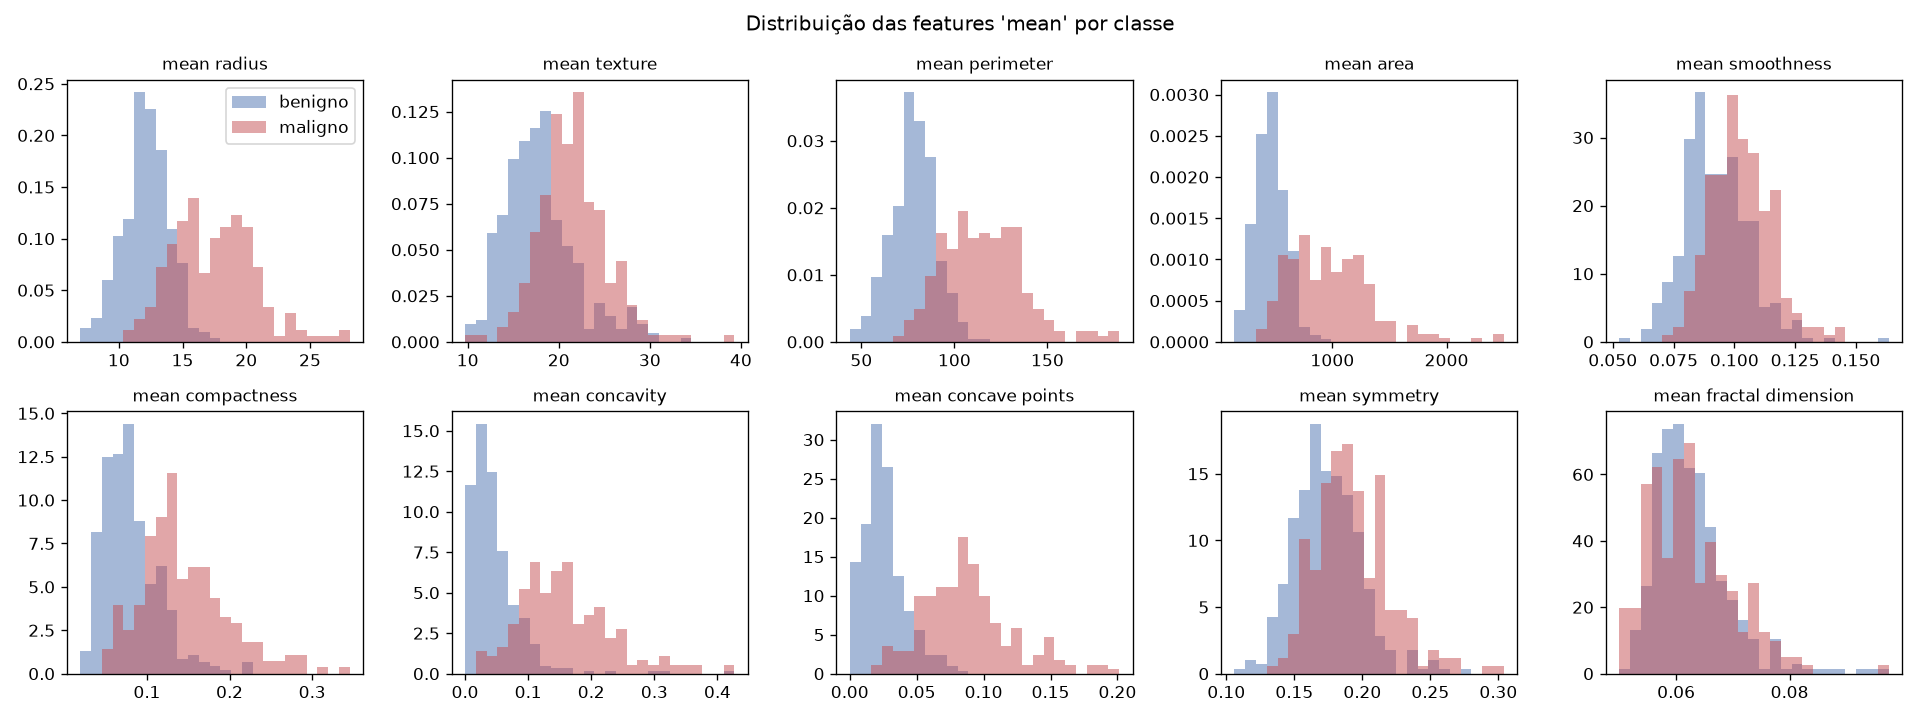

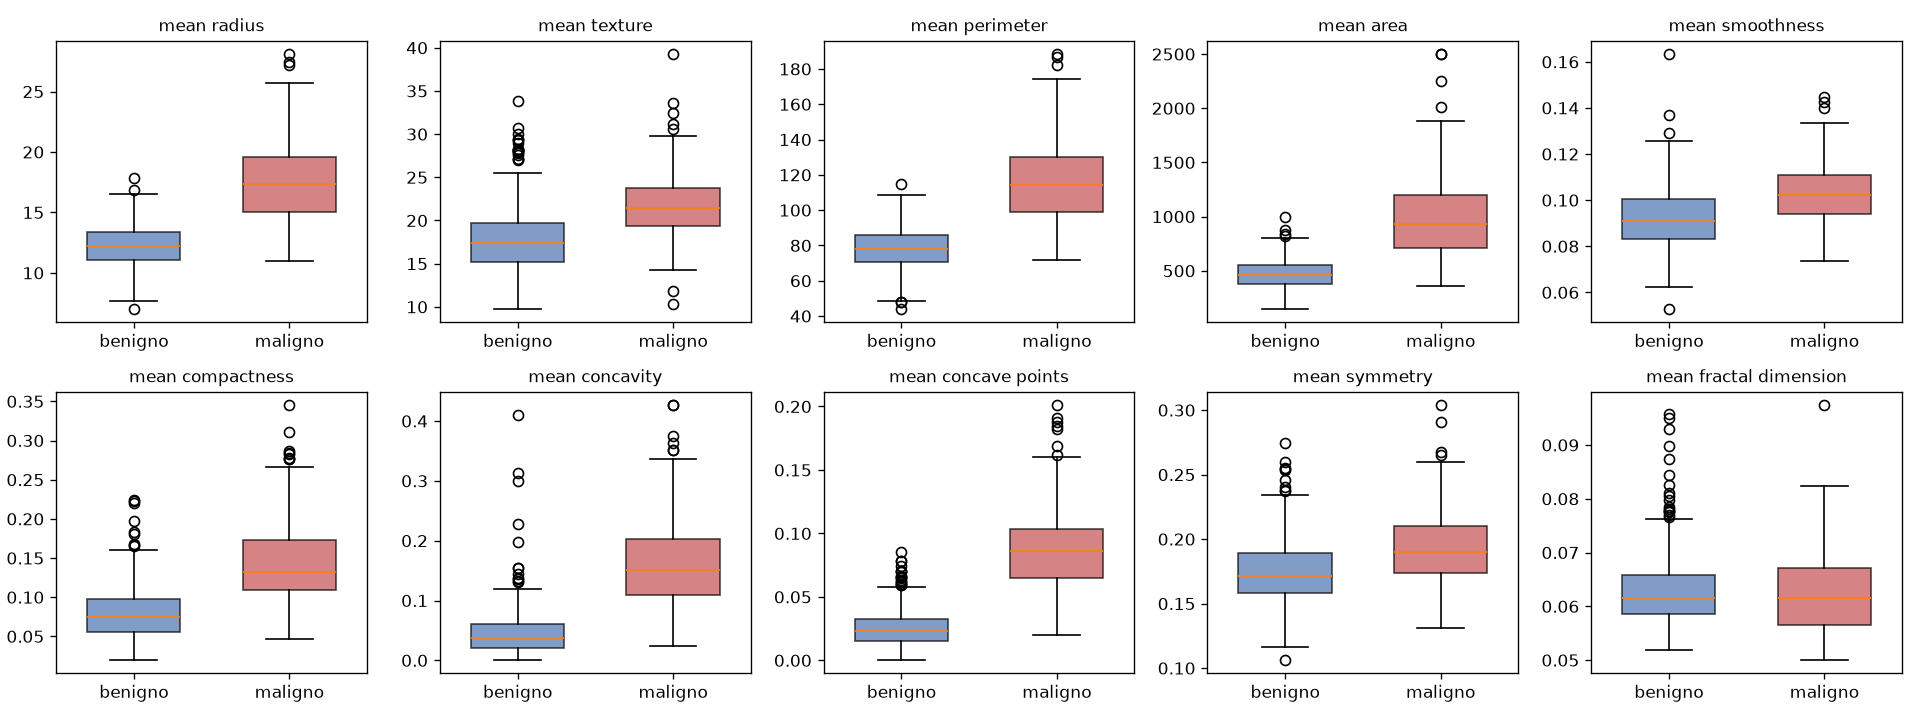

In [4]:
display(Image(eda.plot_distributions(df)))
display(Image(eda.plot_boxplots(df)))

As features de tamanho (`radius`, `perimeter`, `area`) e de irregularidade do contorno (`concavity`,
`concave points`) separam bem as classes. `smoothness`, `symmetry` e `fractal dimension` têm sobreposição elevada.
Os outliers concentram-se na classe maligna e correspondem a tumores grandes, não a erros; foram mantidos.

worst concave points    0.794
worst perimeter         0.783
mean concave points     0.777
worst radius            0.776
mean perimeter          0.743
worst area              0.734
mean radius             0.730
mean area               0.709
mean concavity          0.696
worst concavity         0.660
Name: target, dtype: float64

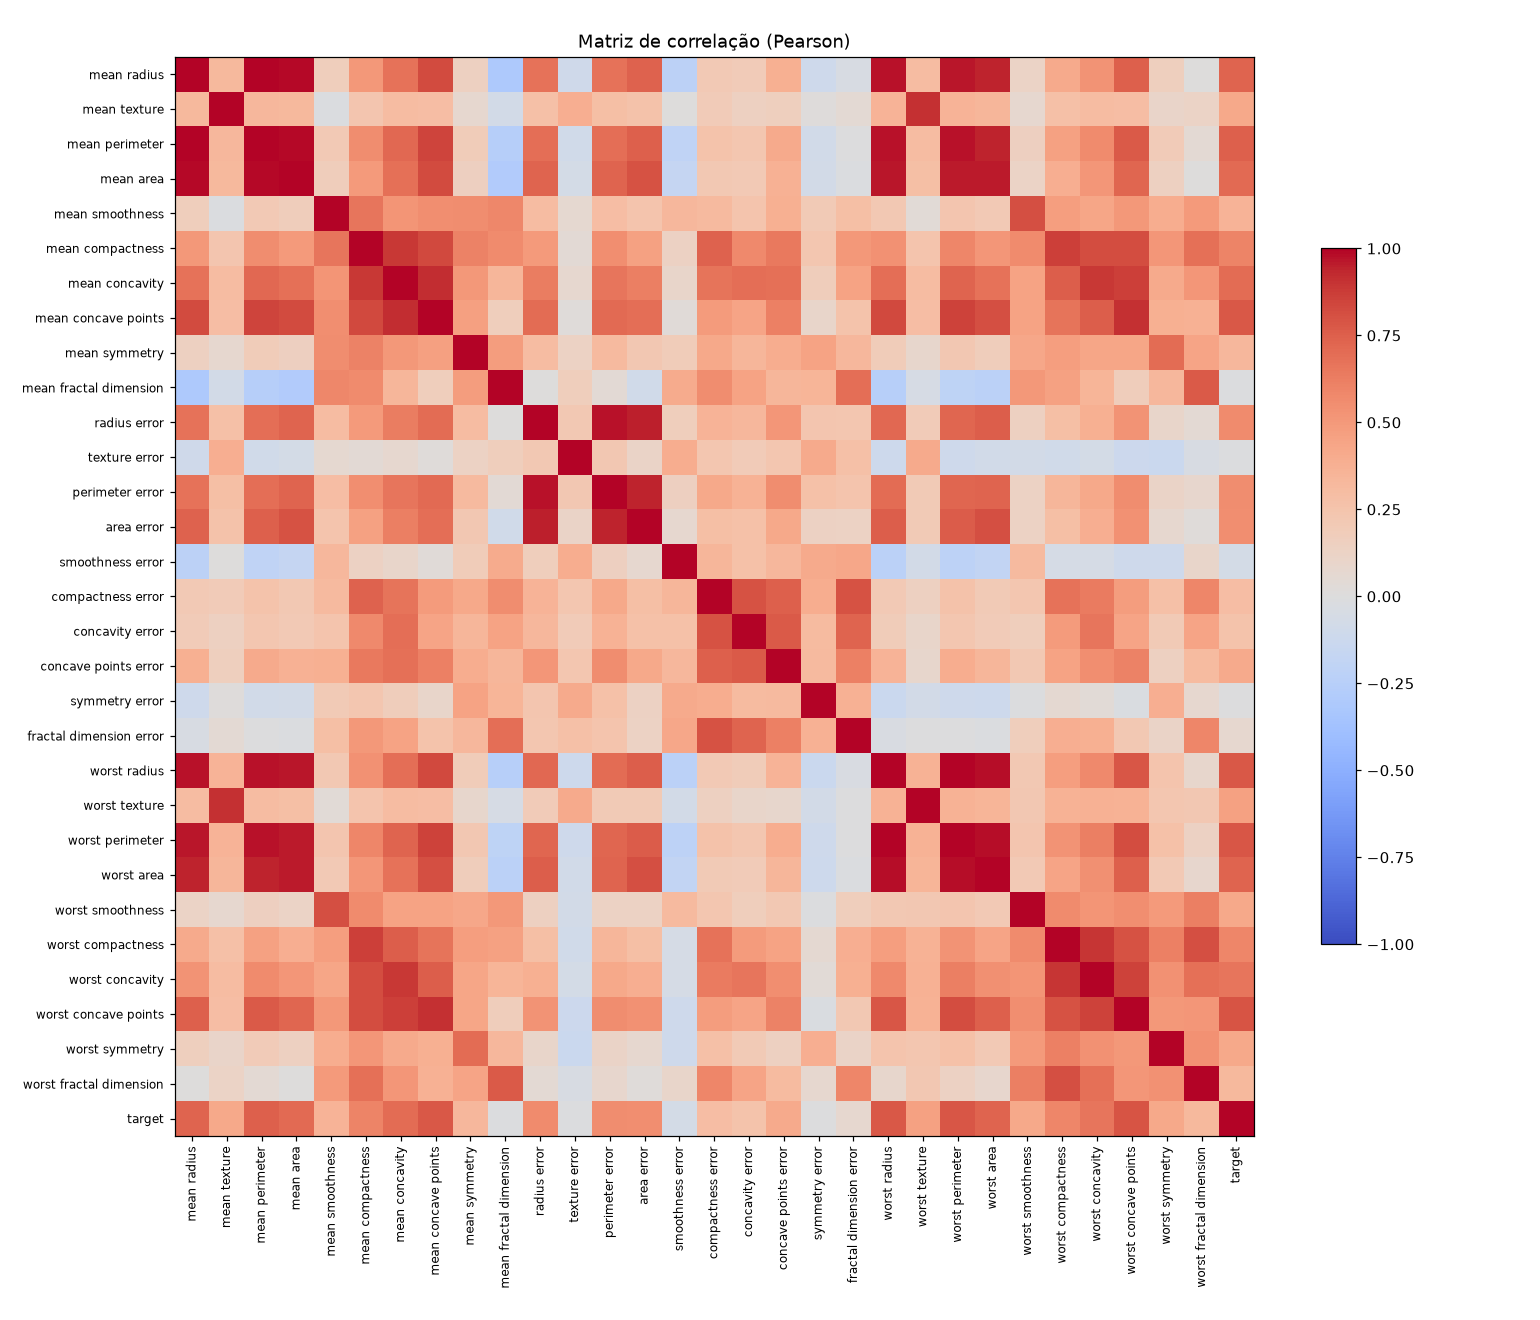

In [5]:
display(eda.top_correlated_with_target(df).round(3))
display(Image(eda.plot_correlation(df)))

Maiores correlações com o alvo: `worst concave points` (0,79), `worst perimeter` (0,78) e `mean concave points`
(0,78). Há multicolinearidade forte (r ≈ 0,99 entre radius, perimeter e area), o que motivou a regularização L2 na
regressão logística e a interpretação das importâncias por grupos de features.

## 3. Pré-processamento e divisão dos dados
- Divisão estratificada 60/20/20 (341/114/114), `random_state=42`.
- `StandardScaler` dentro de um `Pipeline`, ajustado apenas no treino.
- Validação para seleção do modelo; teste usado uma única vez na avaliação final.

In [6]:
X_tr, X_va, X_te, y_tr, y_va, y_te = preprocessing.split_data(df)
pd.DataFrame({"treino": y_tr.value_counts(), "validacao": y_va.value_counts(), "teste": y_te.value_counts()})

,treino,validacao,teste
target,,,
0,214,71,72
1,127,43,42


## 4. Modelos
Regressão Logística (linear, L2) e Random Forest (200 árvores, `class_weight="balanced"`). Métricas na validação:

In [7]:
train.train_all().round(4)

,accuracy,recall,f1
modelo,,,
logistic_regression,0.9737,0.9767,0.9655
random_forest,0.9737,0.9535,0.9647


A Regressão Logística tem o maior recall na validação (42 de 43 malignos) e é selecionada.

## 5. Avaliação no teste
Recall é a métrica prioritária: o falso negativo é o erro de maior custo clínico. F1 penaliza o excesso de falsos
positivos e accuracy é reportada como visão geral.

,accuracy,recall,f1,tn,fp,fn,tp
modelo,,,,,,,
logistic_regression,0.9737,0.9524,0.9639,71,1,2,40
random_forest,0.9737,0.9524,0.9639,71,1,2,40


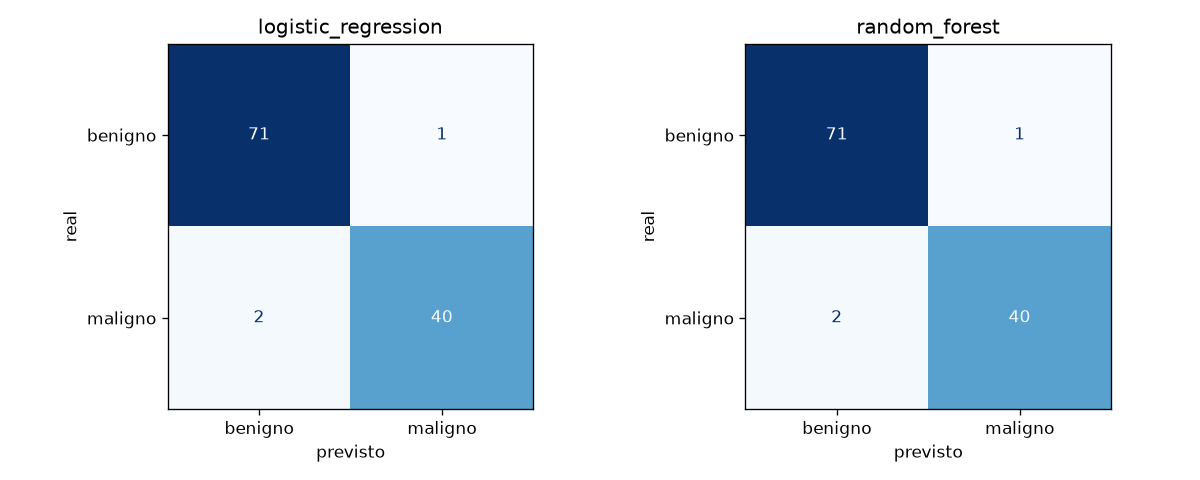

In [8]:
display(evaluate.evaluate_all().round(4))
display(Image(evaluate.plot_confusion_matrices()))

Os dois modelos empatam no teste: 40 de 42 malignos detectados e 1 falso positivo. O intervalo de confiança de
95% para o recall (Wilson) vai de 0,84 a 0,99, então a diferença de um paciente na validação não indica
superioridade. A Regressão Logística é mantida por ser mais simples e interpretável.

In [9]:
evaluate.error_analysis()

,modelo,paciente,real,tipo,prob_maligno
0,logistic_regression,4,0,FP,0.670
1,logistic_regression,16,1,FN,0.070
2,logistic_regression,112,1,FN,0.465
3,random_forest,16,1,FN,0.345
4,random_forest,42,1,FN,0.435
5,random_forest,92,0,FP,0.520


Os modelos erram pacientes diferentes. O paciente #16 é falso negativo nos dois e recebe probabilidade de 7% na
Regressão Logística, um caso maligno com perfil típico de benigno que não é capturado pela faixa de incerteza.

## 6. Interpretação

,logistic_regression,random_forest
worst texture,0.082,0.021
mean concave points,0.067,0.128
radius error,0.062,0.014
worst symmetry,0.058,0.012
worst radius,0.049,0.058
worst area,0.048,0.128
area error,0.048,0.024
worst concavity,0.047,0.039
mean concavity,0.046,0.063
compactness error,0.046,0.004


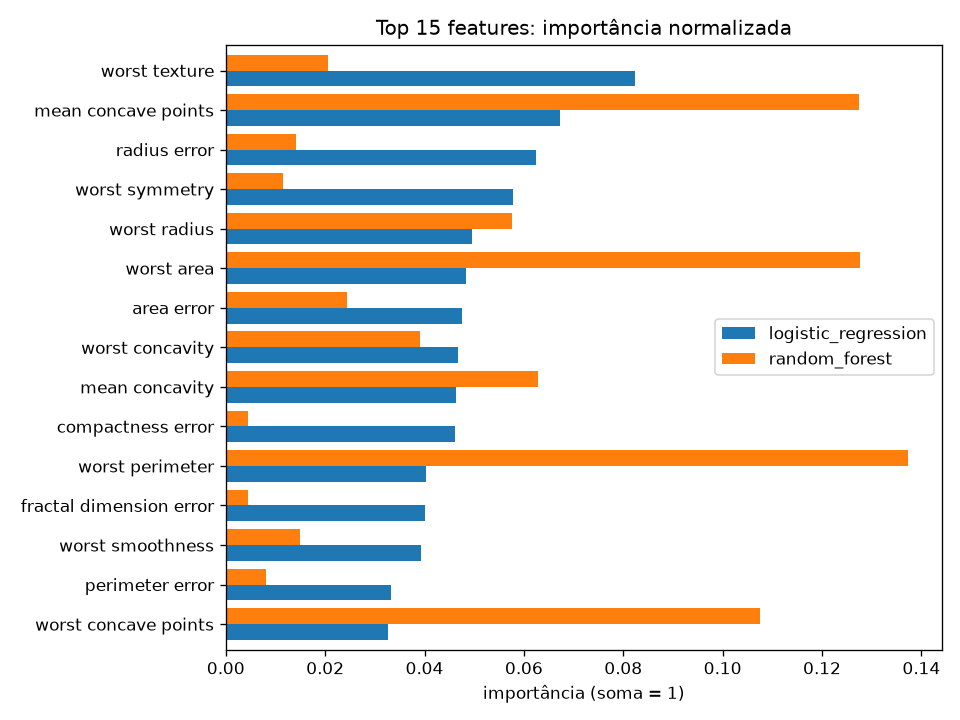

In [10]:
display(explain.feature_importance().head(10).round(3))
display(Image(explain.plot_feature_importance()))

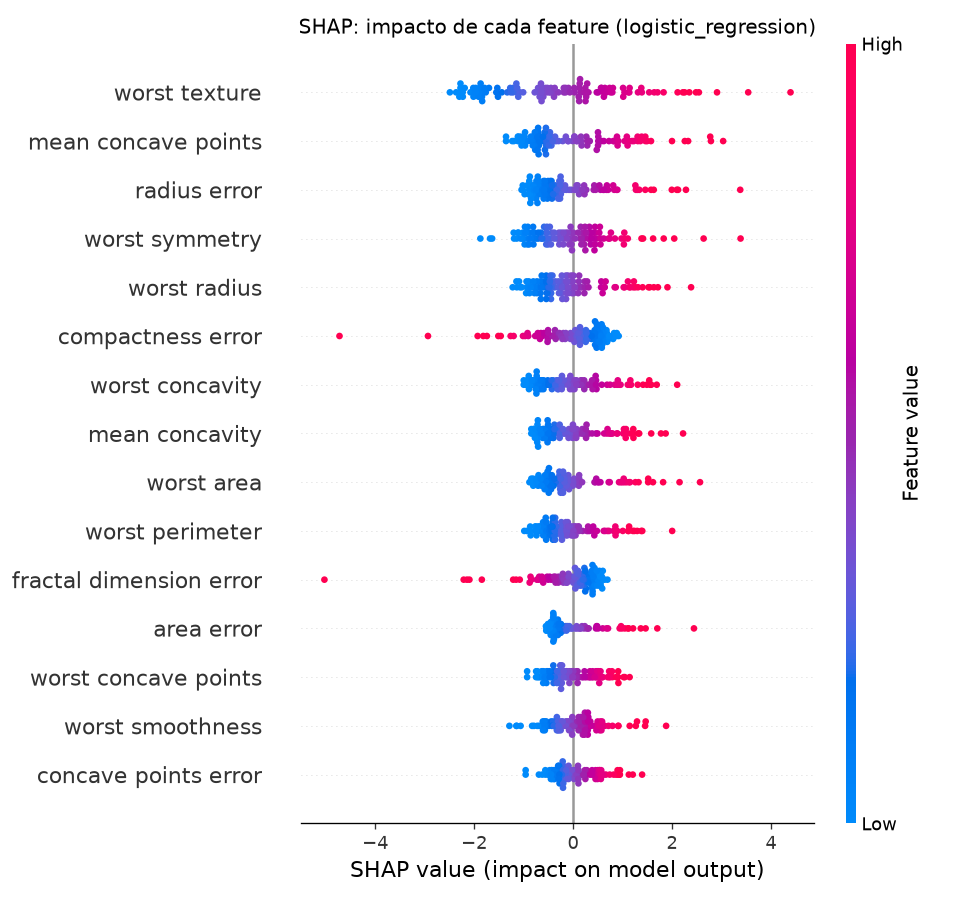

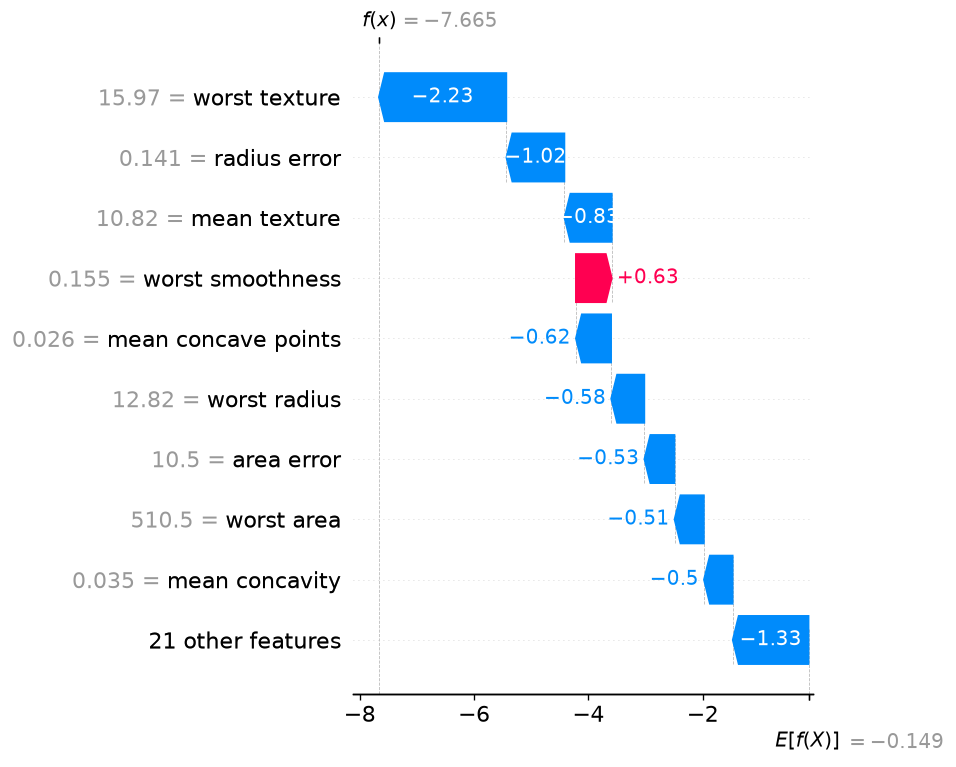

In [11]:
display(Image(explain.plot_shap_summary()))
display(Image(explain.plot_shap_individual(i=0)))

Valores altos de `worst texture`, `mean concave points`, `radius error`, `worst symmetry` e `worst radius`
aumentam a probabilidade de malignidade; `compactness error` e `fractal dimension error` altos a reduzem. O ranking
difere da correlação simples por efeito da multicolinearidade: o peso é distribuído entre features redundantes, e
os coeficientes negativos de algumas features de erro-padrão funcionam como termos de ajuste. O waterfall decompõe
a previsão de um paciente e é o formato exibido na interface.

## 7. Discussão crítica
O modelo é adequado como apoio à triagem, sob supervisão médica, e não como diagnóstico automático.
- Cerca de 5% dos malignos não foram detectados no teste, um deles com probabilidade baixa.
- Dataset pequeno, de um único centro e da década de 1990; o uso real exige validação externa e prospectiva.
- O modelo considera apenas as medidas citológicas, sem histórico, exame físico ou imagem.
- O SHAP explica o comportamento do modelo, não a biologia do tumor.
- O limiar de 0,5 pode ser reduzido para aumentar o recall; essa escolha é clínica e institucional.

Fluxo: exame, modelo (probabilidade), SHAP, avaliação do profissional e decisão final.